
# 02 · Rede

Constrói a rede de fluxo de internações entre os municípios do RN.

**Modelagem**
- **Nó:** município do RN (167)
- **Aresta:** residência → internação, apenas quando os municípios são diferentes
- **Direção:** dirigida (A envia pacientes para B)
- **Peso:** número de internações em 2024
- **Fora da rede:** AIHs de continuação (0,4%); residentes de outros estados (0,9%); internações no próprio município viram o atributo `autossuficiencia` do nó, não um laço

**Saídas:** `data/processed/rede_rn_2024.graphml` e `data/processed/nos_rn_2024.csv`; figura `figures/00_rede_rn.png`

In [1]:
from pathlib import Path

import networkx as nx
import pandas as pd

PROCESSED = Path("data/processed")
ANO = 2024
MIN_VOLUME = 30  # mínimo de internações fora do município para calcular dependência

df = pd.read_parquet(PROCESSED / f"rd_rn_{ANO}.parquet")
municipios = pd.read_csv(PROCESSED / "municipios_rn.csv", dtype={"cod6": str})

## 1. Filtros: AIH normal e residentes do RN

In [2]:
continuacao = df["IDENT"] == "5"
print(f"Removidas (AIH de continuação): {continuacao.sum():,}")
df = df[~continuacao]

fora_do_rn = df["NOME_RES"].isna()
print(f"Removidas (residentes de outros estados): {fora_do_rn.sum():,}")
df = df[~fora_do_rn]

local = df["MUNIC_RES"] == df["MUNIC_MOV"]
print(f"Internações no próprio município: {local.mean():.1%}")
print(f"Internações em outro município:   {(~local).mean():.1%}")

Removidas (AIH de continuação): 891
Removidas (residentes de outros estados): 1,959
Internações no próprio município: 46.0%
Internações em outro município:   54.0%


## 2. Atributos dos nós

- `internacoes_residentes`: total de internações de moradores do município
- `autossuficiencia`: fração dessas internações feita no próprio município

In [3]:
nos = municipios.set_index("cod6")
nos["internacoes_residentes"] = df.groupby("MUNIC_RES").size()
nos["internacoes_locais"] = df[local].groupby("MUNIC_RES").size()
nos = nos.fillna(0).astype({"internacoes_residentes": int, "internacoes_locais": int})
nos["autossuficiencia"] = nos["internacoes_locais"] / nos["internacoes_residentes"]

nos.sort_values("internacoes_residentes", ascending=False).head()

,nome,internacoes_residentes,internacoes_locais,autossuficiencia
cod6,,,,
240810,Natal,47930,46122,0.962278
240800,Mossoró,14407,12921,0.896856
240325,Parnamirim,11268,4620,0.410011
241200,São Gonçalo do Amarante,8489,4104,0.483449
240260,Ceará-Mirim,5942,2886,0.485695


## 3. Arestas: residência → internação

In [4]:
arestas = (df[~local]
           .groupby(["MUNIC_RES", "MUNIC_MOV"]).size()
           .rename("weight").reset_index())

print(f"Arestas: {len(arestas)}")
arestas.nlargest(10, "weight").assign(
    origem=lambda a: a["MUNIC_RES"].map(nos["nome"]),
    destino=lambda a: a["MUNIC_MOV"].map(nos["nome"]),
)

Arestas: 1709


,MUNIC_RES,MUNIC_MOV,weight,origem,destino
379,240325,240810,6420,Parnamirim,Natal
1355,241200,240810,3791,São Gonçalo do Amarante,Natal
787,240710,240810,3049,Macaíba,Natal
308,240260,240810,2701,Ceará-Mirim,Natal
421,240360,240810,2343,Extremoz,Natal
1374,241220,240810,2022,São José de Mipibu,Natal
16,240020,240800,1474,Assú,Mossoró
658,240580,240810,1351,João Câmara,Natal
1626,241440,240810,1338,Touros,Natal
909,240810,240325,1231,Natal,Parnamirim


## 4. Grafo

In [5]:
G = nx.DiGraph()
G.add_nodes_from(nos.index)
G.add_weighted_edges_from(arestas.itertuples(index=False, name=None))

print(G)
print(f"Densidade: {nx.density(G):.4f}")

DiGraph with 167 nodes and 1709 edges
Densidade: 0.0616


## 5. Grau de entrada e de saída

- **Grau:** número de municípios distintos
- **Força (grau ponderado):** número de internações

In [6]:
nos["grau_entrada"] = pd.Series(dict(G.in_degree()))
nos["grau_saida"] = pd.Series(dict(G.out_degree()))
nos["forca_entrada"] = pd.Series(dict(G.in_degree(weight="weight")))
nos["forca_saida"] = pd.Series(dict(G.out_degree(weight="weight")))

recebe = nos["grau_entrada"] > 0
envia = nos["grau_saida"] > 0
print(f"Recebem pacientes de fora: {recebe.sum()}")
print(f"Só enviam:                 {(envia & ~recebe).sum()}")
print(f"Isolados:                  {(~envia & ~recebe).sum()}")

nos.nlargest(10, "forca_entrada")[["nome", "grau_entrada", "forca_entrada", "autossuficiencia"]]

Recebem pacientes de fora: 57
Só enviam:                 110
Isolados:                  0


,nome,grau_entrada,forca_entrada,autossuficiencia
cod6,,,,
240810,Natal,166,61527,0.962278
240800,Mossoró,99,14877,0.896856
240940,Pau dos Ferros,66,5150,0.680645
240325,Parnamirim,154,4981,0.410011
241120,Santa Cruz,111,4083,0.546737
241220,São José de Mipibu,58,3899,0.198099
240310,Currais Novos,145,3382,0.546815
240200,Caicó,61,3185,0.728726
240060,Almino Afonso,128,2741,0.572505


## 6. Dependência de polo único

Entre as internações feitas **fora** do município, a fração que vai para o destino principal. Só para municípios com pelo menos `MIN_VOLUME` internações fora, para evitar frações calculadas sobre poucos casos.

In [7]:
principal = arestas.loc[arestas.groupby("MUNIC_RES")["weight"].idxmax()].set_index("MUNIC_RES")

nos["destino_principal"] = principal["MUNIC_MOV"].map(nos["nome"])
nos["dependencia"] = principal["weight"] / nos["forca_saida"]
nos.loc[nos["forca_saida"] < MIN_VOLUME, "dependencia"] = float("nan")

print(f"Municípios avaliados: {nos['dependencia'].notna().sum()} de {len(nos)}")
print(f"Dependência >= 70%:   {(nos['dependencia'] >= 0.7).sum()}")

nos["destino_principal"].value_counts().head()

Municípios avaliados: 167 de 167
Dependência >= 70%:   28


destino_principal
Natal             95
Mossoró           37
Pau dos Ferros    25
Caicó              9
Parnamirim         1
Name: count, dtype: int64

## 7. Retrato da rede

- **layout geográfico:** cada município fica na posição da sua sede (coordenadas do `01_coleta`), então o desenho é o mapa do RN;
- **só as ligações com pelo menos `PESO_MIN` internações no ano**, que concentram quase todo o fluxo.

Tamanho do nó: internações recebidas de outros municípios. Azul: recebe pacientes de fora; cinza: só envia. Rótulos: os `N_ROTULOS` municípios que mais recebem pacientes de fora.

Ligações com ≥ 50 internações: 401 de 1709, com 89% das internações entre municípios


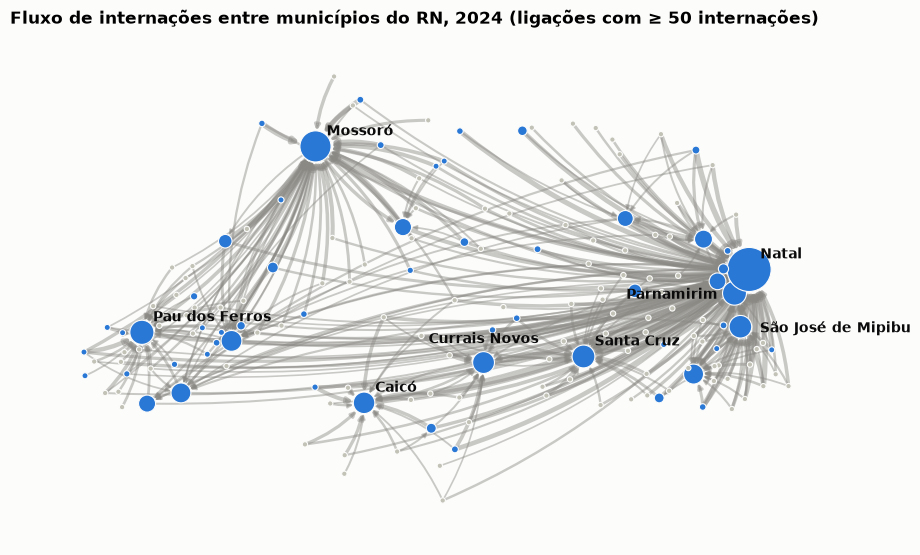

In [8]:
import matplotlib.pyplot as plt
import numpy as np

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
PESO_MIN = 50

coord = pd.read_csv(PROCESSED / "coordenadas_rn.csv", dtype={"cod6": str}).set_index("cod6")
pos = {c: (coord.at[c, "longitude"], coord.at[c, "latitude"]) for c in G}

fortes = [(u, v) for u, v, w in G.edges(data="weight") if w >= PESO_MIN]
peso = np.array([G[u][v]["weight"] for u, v in fortes])
fluxo_mantido = peso.sum() / nos["forca_entrada"].sum()
print(f"Ligações com ≥ {PESO_MIN} internações: {len(fortes)} de {G.number_of_edges()}, "
      f"com {fluxo_mantido:.0%} das internações entre municípios")

nodelist = list(G)
tamanho = [15 + 4 * np.sqrt(nos.at[c, "forca_entrada"]) for c in nodelist]
cor = ["#2a78d6" if nos.at[c, "grau_entrada"] > 0 else "#c3c2b7" for c in nodelist]

fig, ax = plt.subplots(figsize=(11, 7), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
nx.draw_networkx_edges(G, pos, edgelist=fortes, ax=ax, width=0.4 + 2.5 * np.log10(peso / PESO_MIN + 1),
                       edge_color="#8a8984", alpha=0.45, arrows=True, arrowstyle="-|>", arrowsize=7,
                       connectionstyle="arc3,rad=0.12", nodelist=nodelist, node_size=tamanho)
nx.draw_networkx_nodes(G, pos, nodelist=nodelist, node_size=tamanho, node_color=cor,
                       edgecolors="#fcfcfb", linewidths=0.8, ax=ax)
N_ROTULOS = 8
# posição do rótulo: acima e à direita, exceto onde os nós ficam próximos demais
deslocamento = {"Parnamirim": (-12, -4), "São José de Mipibu": (14, -4), "Currais Novos": (0, 14)}
for c in nos["forca_entrada"].nlargest(N_ROTULOS).index:
    cidade = nos.at[c, "nome"]
    dx, dy = deslocamento.get(cidade, (8, 8))
    ax.annotate(cidade, pos[c], xytext=(dx, dy), textcoords="offset points", fontsize=10,
                fontweight="bold", color="#0b0b0b",
                ha="center" if dx == 0 else ("left" if dx > 0 else "right"))
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"Fluxo de internações entre municípios do RN, {ANO} (ligações com ≥ {PESO_MIN} internações)",
             loc="left", fontsize=12, fontweight="bold")
fig.savefig(FIGURES / "00_rede_rn.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Salvar

In [9]:
for cod, attrs in nos.to_dict("index").items():
    G.nodes[cod].update({k: v for k, v in attrs.items() if pd.notna(v)})

nx.write_graphml(G, PROCESSED / f"rede_rn_{ANO}.graphml")
nos.to_csv(PROCESSED / f"nos_rn_{ANO}.csv")